# Sujet 04 · Allstate — Phase 2 · Porteur P1

**Question du projet** : peut-on estimer le montant d'un sinistre (`loss`) à partir de son dossier, et de combien une méthode soignée bat-elle l'estimation « sans modèle » ?

## Les 7 étapes de la phase 2 et les porteurs (tableau blanc, « groupe de 3 »)

| Étape | Titre | Porteur |
|---|---|---|
| 2.1 | **Le découpage** | **P1** |
| 2.2 | La barre de bruit | P2 |
| 2.3 | Le plancher de contrôle | P3 |
| 2.4 | **L'étanchéité** | **P1** |
| 2.5 | Le premier modèle | P2 |
| 2.6 | Les comparaisons | P3 |
| 2.7 | **Le tableau d'essai** | **P1** |

**Enchaînement de P1 : `2.1 → 2.4 → 2.7`.** Ce carnet réalise ces trois étapes pour le sujet 04 :

| Étape | Ce qu'on fait | Section |
|---|---|---|
| 2.1 | fixer **comment on découpe** `train.csv` pour mesurer honnêtement, et le justifier | §1 |
| 2.4 | **prouver** qu'aucune information de la validation ne fuit vers l'entraînement | §2 |
| 2.7 | tenir le **tableau d'essai** (journal) où chaque essai est consigné avec son score, y compris les échecs | §3 |

**Pourquoi P1 est la base des autres.** Tous les essais de P2 (barre de bruit, premier modèle) et de P3 (plancher de contrôle, comparaisons) se mesurent **avec le découpage de 2.1**, et se consignent **dans le tableau de 2.7**. Si le découpage est faux, **tous** les scores de l'équipe sont faux.

**Rappel du tableau blanc : le plancher de contrôle dépend du type de problème.** Classification (binaire ou multiclasse) : la classe majoritaire. **Régression : la médiane.** Prévision : rien, ou la valeur du même jour la semaine précédente. Le sujet 04 est une **régression** : le plancher est donc la **médiane** de `loss` (étape 2.3, P3), et c'est lui qui sert de référence pour les gains du §3.

### Mode d'emploi sur Kaggle
1. Créez un jeu de données privé avec `train.csv` et `a_estimer.csv`.
2. File → Import Notebook, puis **Add Input** → votre jeu de données.
3. Session options : Accelerator **None**, Internet **désactivé**.
4. **Run All**, puis **Save Version → Save & Run All (Commit)**.

Durée d'exécution : quelques minutes (le §3 entraîne trois petits modèles à arbres).

In [1]:
# ============================ FICHE PORTEUR (à remplir) ============================
SEANCE           = "2"                # <- numéro ou date de la séance
NOM              = "Peniel"                    # <- votre nom
PORTEUR          = "P1"                        # <- votre numéro de porteur (phase 2)
ETAPES_ASSIGNEES = ["2.1", "2.4", "2.7"]       # <- les étapes qui vous sont assignées
# ====================================================================================

# --- Réglages du protocole (une cellule = une mutation) ----------------------
N_PLIS     = 5       # nombre de plis de validation croisée
SEED       = 42      # graine : rend le découpage reproductible
N_TRANCHES = 10      # on stratifie sur les déciles de la cible

import os, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import Ridge

pd.set_option("display.width", 150); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 70)
on_kaggle = Path("/kaggle/working").exists()
BASE = "/kaggle/working" if on_kaggle else "."
DATE = pd.Timestamp.today().strftime("%d/%m/%Y")
CIBLE, ID = "loss", "id"
FICHIERS = ["train.csv", "a_estimer.csv"]
RESULTATS = {}
ETAPES = {"2.1": "Le découpage", "2.4": "L'étanchéité", "2.7": "Le tableau d'essai"}

def qui(etape):
    statut = f"assignée à {NOM}" if etape in ETAPES_ASSIGNEES else "NON assignée à cette fiche"
    print(f"▶ Étape {etape} — {ETAPES[etape]} | porteur {PORTEUR} | {statut}")

print("=" * 60)
print(f" Séance            : {SEANCE}")
print(f" Nom               : {NOM}")
print(f" Porteur #         : {PORTEUR}")
print(f" Étapes assignées  : {', '.join(ETAPES_ASSIGNEES)}")
print(f" Date d'exécution  : {DATE}")
print("=" * 60)

 Séance            : 2
 Nom               : Peniel
 Porteur #         : P1
 Étapes assignées  : 2.1, 2.4, 2.7
 Date d'exécution  : 12/11/2026


In [2]:
# --- Localisation et chargement des données ----------------------------------
def trouver_donnees():
    pistes = []
    if os.environ.get("DONNEES_PROJET"): pistes.append(Path(os.environ["DONNEES_PROJET"]))
    ici = Path.cwd().resolve()
    pistes += [ici, ici / "donnees", ici / "Sujet_04_Allstate"] + list(ici.parents)[:3]
    kg = Path("/kaggle/input")
    if kg.exists():
        pistes += [kg] + [d for d in kg.rglob("*") if d.is_dir()][:200]
    for p in pistes:
        if p.exists() and all((p / f).is_file() for f in FICHIERS):
            return p
    raise FileNotFoundError("Dossier introuvable : il faut train.csv et a_estimer.csv. Sur Kaggle : Add Input -> votre jeu de donnees.")

DOSSIER = trouver_donnees()
tr = pd.read_csv(DOSSIER / "train.csv"); te = pd.read_csv(DOSSIER / "a_estimer.csv")
tr[ID] = tr[ID].astype("int64"); te[ID] = te[ID].astype("int64")      # l'id est lu en décimal : on le remet en entier
CAT  = [c for c in tr if c.startswith("cat")]
CONT = [c for c in tr if c.startswith("cont")]
XCOLS = CAT + CONT                                                    # variables explicatives : sans id, sans loss
y = tr[CIBLE].to_numpy()
print("dossier :", DOSSIER, "| train", tr.shape, "| a_estimer", te.shape)
print("variables explicatives :", len(XCOLS), "(id et loss exclus)")

dossier : /kaggle/input/datasets/ahehehinnoupeniel/allstate-sujet4 | train (150654, 132) | a_estimer (37664, 131)
variables explicatives : 130 (id et loss exclus)


---
# §1 · Étape 2.1 — Le découpage

**Ce qu'on cherche.** Dire **comment on coupe** `train.csv` en une partie pour **apprendre** et une partie **cachée** pour **se noter**, de façon à ce que le score mesuré ressemble au score qu'on aurait sur `a_estimer.csv` (dont la vérité est chez l'enseignant).

**Pourquoi c'est la décision la plus importante.** Un score mesuré sur les données utilisées pour apprendre est toujours trop beau (le modèle les a « vues »). Il faut donc **cacher** des lignes. Mais *comment* les cacher change ce que vaut la mesure.

## Les choix, et pourquoi

| Choix | Décision | Justification (appuyée sur les étapes de la phase 1) |
|---|---|---|
| Type de découpage | **aléatoire** (pas temporel, pas par groupes) | 1.8 : les plages d'`id` de `train` et `a_estimer` se chevauchent presque exactement, et leurs distributions sont comparables : `a_estimer` est un **tirage aléatoire** de la même population. 1.7 : pas de doublons à regrouper. |
| Stratification | sur les **déciles de `loss`** | La cible est un **montant**, pas une classe : on ne peut pas stratifier directement dessus, donc on la découpe en tranches de quantiles. Chaque pli a ainsi la **même répartition** de petits et de gros sinistres. |
| Nombre de plis | **5** | Chaque pli de validation fait **20 %** des lignes, la même proportion que `a_estimer` dans l'ensemble (20 %). 5 plis = 5 mesures indépendantes, donc on peut estimer l'**incertitude** du score. |
| Graine | **42**, fixée | Le découpage est **reproductible** : toute l'équipe compare des scores mesurés sur **exactement les mêmes plis**. |

Le découpage est écrit **une seule fois** dans une fonction (`decoupage`) et **sauvegardé** dans un fichier (`plis.csv`) que tous les membres réutilisent.

In [3]:
qui('2.1')

▶ Étape 2.1 — Le découpage | porteur P1 | assignée à Peniel


In [4]:
# --- 2.1 (a) La fonction de découpage -----------------------------------------
def decoupage(y, n_plis=N_PLIS, seed=SEED, tranches=N_TRANCHES):
    """Rend une liste de (indices_apprentissage, indices_validation), un couple par pli."""
    bins = pd.qcut(y, tranches, labels=False, duplicates="drop")        # déciles de la cible
    skf = StratifiedKFold(n_splits=n_plis, shuffle=True, random_state=seed)
    return list(skf.split(np.zeros(len(y)), bins))                     # X n'est pas utilisé : seule la stratification compte

PLIS = decoupage(y)
pli_de_ligne = np.full(len(y), -1)
for k, (a, v) in enumerate(PLIS):
    pli_de_ligne[v] = k

# sauvegarde : un fichier que toute l'équipe peut recharger (id, numéro de pli)
plis_df = pd.DataFrame({ID: tr[ID], "pli": pli_de_ligne})
plis_df.to_csv(Path(BASE) / "plis.csv", index=False)
print("écrit :", Path(BASE) / "plis.csv", "| lignes :", len(plis_df))
print("tailles des plis de validation :", [len(v) for _, v in PLIS])
print("tailles des plis d'apprentissage :", [len(a) for a, _ in PLIS])

écrit : /kaggle/working/plis.csv | lignes : 150654
tailles des plis de validation : [30131, 30131, 30131, 30131, 30130]
tailles des plis d'apprentissage : [120523, 120523, 120523, 120523, 120524]


**Comment lire.** `decoupage` rend, pour chacun des 5 plis, la liste des lignes servant à **apprendre** (`a`) et celle des lignes **cachées** (`v`). Chaque pli de validation compte environ **30 000 lignes**, du même ordre que les 37 664 de `a_estimer` : l'incertitude du score mesuré sera donc comparable à celle du score final. `plis.csv` mémorise à quel pli appartient chaque `id` : n'importe quel membre peut le recharger et obtenir **exactement** le même découpage, même sur un autre ordinateur.

In [5]:
# --- 2.1 (b) Vérifier que le découpage est correct ----------------------------
tous_v = np.concatenate([v for _, v in PLIS])
print("chaque ligne est validée exactement une fois :", len(tous_v) == len(y) and len(np.unique(tous_v)) == len(y))
print("aucun pli sans validation :", all(len(v) > 0 for _, v in PLIS))
print("apprentissage et validation disjoints dans chaque pli :", all(len(set(a) & set(v)) == 0 for a, v in PLIS))

# la cible est-elle bien répartie ? (médiane, moyenne, p90 et nombre de gros sinistres par pli de validation)
lignes = []
for k, (a, v) in enumerate(PLIS):
    lignes.append(dict(pli=k, lignes=len(v), mediane=np.median(y[v]), moyenne=y[v].mean(), p90=np.percentile(y[v], 90),
                       max=y[v].max(), nb_sup_10000=int((y[v] > 10_000).sum()),
                       KS_vs_reste=stats.ks_2samp(y[v], y[a]).statistic))
rep = pd.DataFrame(lignes).set_index("pli")
display(rep.round(3))
print("écart-type entre plis -> médiane :", round(rep.mediane.std(), 2), "| moyenne :", round(rep.moyenne.std(), 2))

chaque ligne est validée exactement une fois : True
aucun pli sans validation : True
apprentissage et validation disjoints dans chaque pli : True


,lignes,mediane,moyenne,p90,max,nb_sup_10000,KS_vs_reste
pli,,,,,,,
0,30131,2115.63,3046.719,6401.670,121012.25,959,0.003
1,30131,2115.32,3048.091,6400.960,106863.00,950,0.003
2,30131,2115.58,3038.150,6402.150,49549.85,944,0.002
3,30131,2115.39,3032.706,6401.290,51127.50,937,0.003
4,30130,2115.63,3028.949,6399.841,45982.60,912,0.003


écart-type entre plis -> médiane : 0.15 | moyenne : 8.42


**Comment lire.**
- Les trois premiers tests doivent valoir `True` : **chaque ligne est notée une fois, jamais avec elle-même dans l'apprentissage**.
- Le tableau compare les plis entre eux : leurs **médianes et moyennes doivent être presque identiques**. C'est l'effet de la stratification. `KS_vs_reste` mesure l'écart entre la distribution d'un pli de validation et celle du reste : il doit être **très proche de 0** (un pli « ressemble » au reste).
- Le nombre de sinistres > 10 000 par pli montre que les **gros sinistres sont répartis** dans tous les plis, pas concentrés dans un seul.

In [6]:
# --- 2.1 (c) Pourquoi la stratification ? comparaison avec un découpage non stratifié --
def stabilite(plis):
    med = [np.median(y[v]) for _, v in plis]; moy = [y[v].mean() for _, v in plis]
    return np.std(med), np.std(moy)

simple = list(KFold(N_PLIS, shuffle=True, random_state=SEED).split(y))
comp = pd.DataFrame({"KFold simple": stabilite(simple), "StratifiedKFold (déciles)": stabilite(PLIS)},
                    index=["écart-type de la médiane entre plis", "écart-type de la moyenne entre plis"]).round(2)
display(comp)

# on répète avec 20 graines différentes : la stratification est-elle meilleure systématiquement ?
sd_simple = [stabilite(list(KFold(N_PLIS, shuffle=True, random_state=s).split(y)))[0] for s in range(20)]
sd_strat  = [stabilite(decoupage(y, seed=s))[0] for s in range(20)]
print(f"sur 20 graines — écart-type de la médiane entre plis : KFold simple {np.mean(sd_simple):.2f} | stratifié {np.mean(sd_strat):.2f}")
print("la stratification est meilleure dans", sum(a > b for a, b in zip(sd_simple, sd_strat)), "tirages sur 20")

,KFold simple,StratifiedKFold (déciles)
écart-type de la médiane entre plis,17.46,0.13
écart-type de la moyenne entre plis,26.87,7.53


sur 20 graines — écart-type de la médiane entre plis : KFold simple 10.95 | stratifié 0.13
la stratification est meilleure dans 20 tirages sur 20


**Comment lire.** Sans stratification, la médiane de `loss` **varie davantage** d'un pli à l'autre : par pur hasard, certains plis reçoivent plus de gros sinistres. Un modèle noté sur un pli « chanceux » paraîtrait meilleur, sans l'être. Avec la stratification, tous les plis sont **comparables**, donc les écarts de score entre deux modèles reflètent le modèle, pas le tirage. La répétition sur 20 graines montre que ce n'est pas un coup de chance sur la graine 42.

In [7]:
# --- 2.1 (d) Cas particulier : les lignes jumelles (étape 1.7) ----------------
jum = tr.duplicated(subset=XCOLS, keep=False)
print("lignes dont les 130 variables sont identiques à une autre ligne :", int(jum.sum()))
if jum.any():
    print("plis auxquels appartiennent ces lignes :", pli_de_ligne[jum.to_numpy()].tolist())
    memes = len(set(pli_de_ligne[jum.to_numpy()])) == 1
    print("-> les jumeaux sont dans le MÊME pli : aucun ne sert à apprendre l'autre." if memes else
          "-> les jumeaux sont dans des plis DIFFÉRENTS : effet négligeable (2 lignes sur 150 654).")

RESULTATS["2.1_decoupage"] = dict(type="StratifiedKFold sur déciles de loss", n_plis=N_PLIS, graine=SEED,
    taille_pli_validation=[len(v) for _, v in PLIS], sd_mediane_plis=round(float(rep.mediane.std()), 2),
    sd_mediane_plis_sans_stratification=round(float(stabilite(simple)[0]), 2), fichier_plis="plis.csv")
print(f"\nConclusion 2.1 : StratifiedKFold {N_PLIS} plis sur déciles de loss, graine {SEED}, fichier plis.csv. "
      f"Écart-type de la médiane entre plis : {rep.mediane.std():.2f} (contre {stabilite(simple)[0]:.2f} sans stratification).")

lignes dont les 130 variables sont identiques à une autre ligne : 2
plis auxquels appartiennent ces lignes : [1, 1]
-> les jumeaux sont dans le MÊME pli : aucun ne sert à apprendre l'autre.

Conclusion 2.1 : StratifiedKFold 5 plis sur déciles de loss, graine 42, fichier plis.csv. Écart-type de la médiane entre plis : 0.15 (contre 17.46 sans stratification).


> **Conclusion 2.1 (journal)** : validation croisée **aléatoire stratifiée sur les déciles de `loss`**, 5 plis de ≈ 30 000 lignes (20 %, comme `a_estimer`), graine 42, découpage sauvegardé dans `plis.csv`. Choix justifié par : `a_estimer` est un tirage aléatoire de la même population (1.8) ; la cible est un montant à stratifier par quantiles ; la stratification rend les plis comparables (la ligne affichée ci-dessus donne l'écart-type de la médiane entre plis, avant/après). Pas de regroupement des jumeaux (2 lignes seulement, 1.7).

---
# §2 · Étape 2.4 — L'étanchéité

**Ce qu'on cherche.** Le découpage de 2.1 cache des lignes. L'**étanchéité**, c'est la garantie qu'**aucune information venant de ces lignes cachées ne s'est glissée dans l'apprentissage**. Une « fuite » rend le score faux (trop beau) **sans qu'aucune erreur ne s'affiche**.

**Analogie.** Un examen où l'élève a vu le sujet avant : la note est excellente, mais elle ne mesure plus rien. L'étanchéité, c'est vérifier que la salle d'examen est bien fermée.

**Où les fuites se cachent** (toutes les situations suivantes ont déjà gâché des projets réels) :
1. des lignes **présentes à la fois** dans l'apprentissage et la validation ;
2. des lignes **identiques** (jumeaux) de part et d'autre ;
3. un **prétraitement appris sur tout `train`** avant le découpage (ex. une moyenne par modalité calculée avec la cible) ;
4. la **cible** (ou un dérivé) glissée parmi les variables ;
5. un réglage fait **en regardant** le score de validation.

La règle d'or : **tout ce qui utilise `loss` doit être calculé à l'intérieur de chaque pli, sur les lignes d'apprentissage seulement.**

In [8]:
qui('2.4')

▶ Étape 2.4 — L'étanchéité | porteur P1 | assignée à Peniel


In [9]:
# --- 2.4 (a) Check-list automatique d'étanchéité -------------------------------
tests = []
def test(nom, ok, detail=""): tests.append(dict(contrôle=nom, réussi=bool(ok), détail=detail))

# 1) indices et identifiants disjoints
test("indices apprentissage / validation disjoints (5 plis)", all(len(set(a) & set(v)) == 0 for a, v in PLIS))
test("id apprentissage / validation disjoints (5 plis)", all(len(set(tr[ID].iloc[a]) & set(tr[ID].iloc[v])) == 0 for a, v in PLIS))

# 2) pas de jumeaux entre apprentissage et validation
h = pd.util.hash_pandas_object(tr[XCOLS], index=False).to_numpy()
twins = sum(int(np.isin(h[v], h[a]).sum()) for a, v in PLIS)
test("lignes de validation ayant un jumeau exact dans l'apprentissage", twins == 0, f"{twins} cas sur {len(y):,}")

# 3) train / a_estimer : pas de lignes communes (sinon la soumission « tricherait »)
h_te = pd.util.hash_pandas_object(te[XCOLS], index=False).to_numpy()
test("lignes de a_estimer ayant un jumeau dans train", int(np.isin(h_te, h).sum()) == 0, f"{int(np.isin(h_te, h).sum())} cas")
test("id communs entre train et a_estimer", len(set(tr[ID]) & set(te[ID])) == 0)

# 4) la cible n'est pas dans les variables
test("`loss` absent des variables explicatives", CIBLE not in XCOLS)
test("`id` absent des variables explicatives", ID not in XCOLS)
test("`loss` absent de a_estimer", CIBLE not in te.columns)

# 5) aucune colonne ne ressemble à la cible
r = max(abs(np.corrcoef(tr[c], y)[0, 1]) for c in CONT)
test("aucune continue quasi égale à la cible (|corrélation| < 0,9)", r < 0.9, f"corrélation maximale = {r:.3f}")

T = pd.DataFrame(tests)
T["réussi"] = T["réussi"].map({True: "✔", False: "✘ ÉCHEC"})
display(T)
print("tous les contrôles réussis :", bool((T["réussi"] == "✔").all()))

,contrôle,réussi,détail
0,indices apprentissage / validation disjoints (5 plis),✔,
1,id apprentissage / validation disjoints (5 plis),✔,
2,lignes de validation ayant un jumeau exact dans l'apprentissage,✔,"0 cas sur 150,654"
3,lignes de a_estimer ayant un jumeau dans train,✔,0 cas
4,id communs entre train et a_estimer,✔,
5,`loss` absent des variables explicatives,✔,
6,`id` absent des variables explicatives,✔,
7,`loss` absent de a_estimer,✔,
8,"aucune continue quasi égale à la cible (|corrélation| < 0,9)",✔,corrélation maximale = 0.141


tous les contrôles réussis : True


**Comment lire.** Chaque ligne est un **test automatique** : `✔` = réussi, `✘ ÉCHEC` = fuite détectée (à corriger avant d'aller plus loin). Ces tests peuvent être **relancés à chaque modification** du pipeline. Ils couvrent les fuites **visibles**. Les fuites **subtiles** (prétraitement appris avec la cible) ne se voient pas dans les indices : on les détecte par l'expérience du **canari**, juste en dessous.

In [10]:
# --- 2.4 (b) Le canari : une fuite subtile, rendue visible --------------------
# On construit une règle de prédiction « médiane de loss pour chaque combinaison de 4 variables à modalités nombreuses ».
# Les groupes sont très petits, donc la règle peut MÉMORISER la cible : c'est un détecteur de fuite très sensible.
cle = tr["cat116"] + "|" + tr["cat110"] + "|" + tr["cat112"] + "|" + tr["cat113"]
print("nombre de groupes distincts :", cle.nunique(), "| taille médiane d'un groupe :", int(cle.value_counts().median()))

def predire_par_groupe(y_ref, a, v, fuite):
    ref = np.arange(len(y_ref)) if fuite else a                 # fuite=True : la règle est apprise avec TOUTES les lignes, validation incluse
    g = pd.Series(y_ref[ref]).groupby(cle.iloc[ref].values).median()
    return cle.iloc[v].map(g).fillna(np.median(y_ref[ref])).to_numpy()

def mae_plis(y_ref, fuite):
    return np.mean([np.abs(y_ref[v] - predire_par_groupe(y_ref, a, v, fuite)).mean() for a, v in PLIS])

def plancher_plis(y_ref):
    return np.mean([np.abs(y_ref[v] - np.median(y_ref[a])).mean() for a, v in PLIS])

rng = np.random.default_rng(0)
y_melange = rng.permutation(y)             # la même cible, mais ATTRIBUÉE AU HASARD : plus aucun lien avec les variables

lignes = []
for nom_y, yy in [("vraie cible", y), ("cible MÉLANGÉE (aucun signal)", y_melange)]:
    base = plancher_plis(yy)
    for nom_p, fuite in [("étanche (appris dans le pli)", False), ("AVEC FUITE (appris sur tout)", True)]:
        m = mae_plis(yy, fuite)
        lignes.append(dict(cible=nom_y, procédure=nom_p, MAE=round(m, 1), plancher=round(base, 1), gain=f"{1 - m / base:+.1%}"))
canari = pd.DataFrame(lignes)
display(canari)

nombre de groupes distincts : 31230 | taille médiane d'un groupe : 2


,cible,procédure,MAE,plancher,gain
0,vraie cible,étanche (appris dans le pli),1944.3,1810.5,-7.4%
1,vraie cible,AVEC FUITE (appris sur tout),1488.5,1810.5,+17.8%
2,cible MÉLANGÉE (aucun signal),étanche (appris dans le pli),1994.7,1810.5,-10.2%
3,cible MÉLANGÉE (aucun signal),AVEC FUITE (appris sur tout),1507.3,1810.5,+16.7%


**Comment lire (c'est la clé de l'étape 2.4).**
- **Cible mélangée** = on a détruit tout lien entre les variables et le montant : **aucune méthode honnête ne peut faire mieux que le plancher** (gain ≈ 0 %, voire négatif). C'est le « canari ».
- Ligne **étanche** avec la cible mélangée : le gain doit rester **proche de 0 ou négatif**. ✔ = la procédure est saine, elle ne « trouve » pas de signal là où il n'y en a pas.
- Ligne **AVEC FUITE** avec la cible mélangée : le gain devient **fortement positif, alors qu'il n'y a aucun signal à trouver**. C'est la preuve qu'une procédure fuyante **invente** de la performance : la règle a simplement **mémorisé** les montants des lignes qu'elle devait deviner.
- Avec la **vraie cible**, la même fuite donne un score **artificiellement meilleur** que la procédure étanche : c'est l'ampleur du mensonge qu'on évite.

**Test à refaire pour vos propres pipelines** : mélangez la cible et relancez votre procédure ; si elle « gagne » sur le plancher, il y a une fuite quelque part.

In [11]:
# --- 2.4 (c) Combien la fuite fausse-t-elle le score ? ------------------------
vrai = canari[canari["cible"] == "vraie cible"].set_index("procédure")["MAE"]
print(f"vraie cible — étanche : {vrai.iloc[0]:.1f} | avec fuite : {vrai.iloc[1]:.1f} "
      f"-> la fuite améliore artificiellement le score de {vrai.iloc[0] - vrai.iloc[1]:.0f} points de MAE ({1 - vrai.iloc[1] / vrai.iloc[0]:.1%})")
fuite_melange = canari[(canari["cible"] != "vraie cible") & canari["procédure"].str.startswith("AVEC")]["gain"].iloc[0]
sain_melange  = canari[(canari["cible"] != "vraie cible") & canari["procédure"].str.startswith("étanche")]["gain"].iloc[0]
print(f"cible mélangée — gain affiché par la procédure étanche : {sain_melange} (attendu ≈ 0 ou négatif) | par la procédure fuyante : {fuite_melange} (faux)")

RESULTATS["2.4_etancheite"] = dict(controles_reussis=int((T["réussi"] == "✔").sum()), controles_total=len(T),
    jumeaux_train_validation=int(twins), canari=canari.to_dict("records"))
print(f"\nConclusion 2.4 : {int((T['réussi'] == '✔').sum())}/{len(T)} contrôles réussis ; canari : la procédure étanche affiche {sain_melange} sur cible mélangée, la procédure fuyante {fuite_melange}.")

vraie cible — étanche : 1944.3 | avec fuite : 1488.5 -> la fuite améliore artificiellement le score de 456 points de MAE (23.4%)
cible mélangée — gain affiché par la procédure étanche : -10.2% (attendu ≈ 0 ou négatif) | par la procédure fuyante : +16.7% (faux)

Conclusion 2.4 : 9/9 contrôles réussis ; canari : la procédure étanche affiche -10.2% sur cible mélangée, la procédure fuyante +16.7%.


> **Conclusion 2.4 (journal)** : tous les contrôles d'étanchéité sont automatisés (indices et `id` disjoints, aucun jumeau entre apprentissage et validation, aucune ligne commune `train`/`a_estimer`, cible absente des variables). Le test du **canari** (cible mélangée) montre qu'une procédure étanche n'invente pas de performance (gain ≈ 0), alors qu'une procédure fuyante en invente beaucoup ; **règle retenue : toute statistique qui utilise `loss` est calculée à l'intérieur de chaque pli**. Les chiffres exacts sont affichés par la dernière cellule ci-dessus. L'encodage ordinal des catégorielles n'utilise **pas** la cible (il peut donc être ajusté sur `train` + `a_estimer`) ; un encodage fondé sur la cible, lui, devra toujours être appris dans le pli.

---
# §3 · Étape 2.7 — Le tableau d'essai

**Ce qu'on cherche.** Un **journal chiffré** : chaque essai a son idée, sa configuration, son score **mesuré avec le découpage de 2.1**, sa durée et un verdict honnête. Le sujet impose **au moins huit essais, dont ceux qui ont échoué**, et note la **« vérité du journal »**.

**Règles du tableau** :
1. **même découpage** pour tous les essais (`PLIS`, §1) : seuls les scores mesurés ainsi sont comparables ;
2. **même métrique** : MAE (erreur absolue moyenne), moyenne sur les 5 plis, avec l'**écart-type** (l'incertitude) ;
3. **gain exprimé par rapport au plancher** : `1 − MAE / MAE_plancher` (le plancher est la constante médiane, calculée dans les plis) ;
4. **on n'efface rien** : un essai raté ou invalide reste dans le tableau, avec son verdict.

La fonction `consigner(...)` ci-dessous fait tout cela d'un coup : on lui donne le nom, l'idée et une fonction de prédiction, elle mesure et range le résultat. **Ajouter un essai = appeler `consigner` une fois.**

In [12]:
qui('2.7')

▶ Étape 2.7 — Le tableau d'essai | porteur P1 | assignée à Peniel


In [13]:
# --- 2.7 (a) Le journal et la fonction qui mesure ------------------------------
JOURNAL = []

def consigner(nom, idee, fit_predict, verdict="", statut="valide"):
    """Mesure un essai avec le découpage commun et l'ajoute au journal.
    fit_predict(a, v) -> prédictions pour les lignes v (échelle d'origine), en n'utilisant que les lignes a pour apprendre."""
    t0 = time.time(); scores = []
    for a, v in PLIS:
        p = np.asarray(fit_predict(a, v), dtype=float)
        scores.append(float(np.mean(np.abs(y[v] - p))))
    JOURNAL.append(dict(n=len(JOURNAL) + 1, essai=nom, idée=idee, MAE=round(np.mean(scores), 1), écart_type=round(np.std(scores), 1),
                        durée_s=round(time.time() - t0), statut=statut, verdict=verdict, _plis=scores))
    r = JOURNAL[-1]; print(f"essai {r['n']} · {nom} : MAE = {r['MAE']} ± {r['écart_type']} ({r['durée_s']} s) [{statut}]")
    return r

# préparation commune des variables (sans utiliser la cible : pas de fuite)
enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1).fit(pd.concat([tr[CAT], te[CAT]]))
X_ord = tr[XCOLS].copy(); X_ord[CAT] = enc.transform(tr[CAT])
MASQUE = [(c in CAT) and (len(enc.categories_[CAT.index(c)]) <= 255) for c in XCOLS]     # limite scikit-learn : 255 modalités en natif
print("variables catégorielles natives :", sum(MASQUE), "| traitées en numérique (> 255 modalités) :", sum(c in CAT for c in XCOLS) - sum(MASQUE))

variables catégorielles natives : 115 | traitées en numérique (> 255 modalités) : 1


**Comment lire.** `consigner` applique à chaque essai **exactement** la même boucle de mesure : c'est ce qui garantit des scores comparables. Les variables catégorielles sont transformées en entiers par un `OrdinalEncoder` qui **n'utilise pas la cible** (donc aucune fuite). Les variables à plus de 255 modalités (ici `cat116`) sont traitées comme numériques, car le modèle à arbres de scikit-learn refuse davantage en mode « catégoriel natif ».

In [14]:
# --- 2.7 (b) Les essais « sans modèle » ou presque -----------------------------
c1 = tr["cat80"].astype(str)                                   # une variable à 2 modalités, meilleure seule (voir plancher P2)
def mediane_groupe(cle_, fuite=False):
    def f(a, v):
        ref = np.arange(len(y)) if fuite else a
        g = pd.Series(y[ref]).groupby(cle_.iloc[ref].values).median()
        return cle_.iloc[v].map(g).fillna(np.median(y[ref])).to_numpy()
    return f

consigner("Constante médiane", "annoncer la médiane de l'apprentissage à tout le monde",
          lambda a, v: np.full(len(v), np.median(y[a])), "PLANCHER : valeur à battre", "référence")
PLANCHER = JOURNAL[0]["MAE"]
consigner("Constante moyenne", "annoncer la moyenne à tout le monde",
          lambda a, v: np.full(len(v), y[a].mean()), "moins bon que la médiane : la moyenne est tirée par les gros sinistres (échec attendu)")
consigner("Médiane par cat80", "médiane de loss du groupe défini par cat80 (une seule variable)", mediane_groupe(c1),
          "gain modeste mais réel : une variable seule apporte déjà quelque chose")
consigner("Médiane par groupe combiné (étanche)", "médiane par combinaison de cat116, cat110, cat112, cat113, apprise dans le pli", mediane_groupe(cle),
          "groupes trop petits : la règle apprend du bruit (sur-apprentissage)")
consigner("Médiane par groupe combiné (AVEC FUITE)", "même règle, mais apprise sur TOUTES les lignes, validation comprise", mediane_groupe(cle, fuite=True),
          "INVALIDE : score faussé par fuite (voir canari 2.4). Conservé pour mémoire, jamais à retenir.", "INVALIDE (fuite)")

essai 1 · Constante médiane : MAE = 1810.5 ± 7.8 (0 s) [référence]
essai 2 · Constante moyenne : MAE = 1968.1 ± 7.3 (0 s) [valide]
essai 3 · Médiane par cat80 : MAE = 1565.2 ± 6.4 (0 s) [valide]
essai 4 · Médiane par groupe combiné (étanche) : MAE = 1944.3 ± 8.4 (0 s) [valide]
essai 5 · Médiane par groupe combiné (AVEC FUITE) : MAE = 1488.5 ± 8.4 (0 s) [INVALIDE (fuite)]


{'n': 5,
 'essai': 'Médiane par groupe combiné (AVEC FUITE)',
 'idée': 'même règle, mais apprise sur TOUTES les lignes, validation comprise',
 'MAE': np.float64(1488.5),
 'écart_type': np.float64(8.4),
 'durée_s': 0,
 'statut': 'INVALIDE (fuite)',
 'verdict': 'INVALIDE : score faussé par fuite (voir canari 2.4). Conservé pour mémoire, jamais à retenir.',
 '_plis': [1484.552237562643,
  1499.0276358235703,
  1480.5499244963657,
  1479.9834091135374,
  1498.191311981414]}

**Comment lire.** Le premier essai est le **plancher** : on mesure la constante médiane avec **le même protocole** que les autres. Les essais 2 à 4 montrent trois comportements : (2) un **échec attendu** (la moyenne est moins bonne que la médiane pour la MAE) ; (3) une **règle simple qui apporte déjà un gain** ; (4) un **sur-apprentissage** (des groupes trop fins mémorisent le bruit). L'essai 5 est **volontairement fautif** : il montre à quoi ressemble un score faussé par une fuite, et pourquoi on l'étiquette `INVALIDE`, sans le supprimer.

In [15]:
# --- 2.7 (c) Les essais « modèle » --------------------------------------------
# Ridge (régression linéaire régularisée) : variables à ≤ 50 modalités en one-hot + 14 continues standardisées
CAT_PEU = [c for c in CAT if tr[c].nunique() <= 50]
def ridge(a, v):
    pre = ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT_PEU), ("num", StandardScaler(), CONT)])
    Xa = pre.fit_transform(tr.iloc[a][CAT_PEU + CONT]); Xv = pre.transform(tr.iloc[v][CAT_PEU + CONT])
    m = Ridge(alpha=10.0, solver="sparse_cg").fit(Xa, np.log1p(y[a]))
    return np.expm1(m.predict(Xv))
consigner("Ridge sur log(1+loss)", "régression linéaire régularisée, one-hot des catégorielles à ≤ 50 modalités", ridge,
          "bon repère linéaire : déjà un gros gain sur le plancher, mais les arbres font nettement mieux (interactions entre variables)")

def hgb(perte, cible_log, iters=150):
    def f(a, v):
        m = HistGradientBoostingRegressor(loss=perte, learning_rate=0.1, max_iter=iters, max_leaf_nodes=31, min_samples_leaf=40,
                                          categorical_features=MASQUE, early_stopping=False, random_state=SEED)
        m.fit(X_ord.iloc[a], np.log1p(y[a]) if cible_log else y[a])
        p = m.predict(X_ord.iloc[v]); return np.expm1(p) if cible_log else p
    return f

consigner("Arbres (HGB) · perte absolue · cible brute", "HistGradientBoosting, loss='absolute_error', 150 itérations", hgb("absolute_error", False),
          "bon : la perte absolue vise directement la métrique")
consigner("Arbres (HGB) · perte absolue · log(1+loss)", "même modèle sur la cible transformée par log(1+loss)", hgb("absolute_error", True),
          "meilleur : la médiane est conservée par le log, et la cible est plus facile à modéliser en log")
consigner("Arbres (HGB) · perte quadratique · log(1+loss)", "log(1+loss) mais perte quadratique (mauvaise perte pour la MAE)", hgb("squared_error", True),
          "équivalent à l'essai 8 (écart < écart-type) : en log, la cible est quasi symétrique (moyenne ≈ médiane), la perte quadratique n'est donc pas pénalisante ici")
consigner("Arbres (HGB) · perte quadratique · cible brute", "loss='squared_error' sur la cible brute, mais notée en MAE : incohérence perte/métrique", hgb("squared_error", False),
          "moins bon que la perte absolue sur la même cible : la perte quadratique vise la moyenne, or la métrique récompense la médiane (échec instructif)")

essai 6 · Ridge sur log(1+loss) : MAE = 1263.5 ± 8.2 (75 s) [valide]
essai 7 · Arbres (HGB) · perte absolue · cible brute : MAE = 1164.0 ± 5.5 (72 s) [valide]
essai 8 · Arbres (HGB) · perte absolue · log(1+loss) : MAE = 1156.4 ± 5.9 (72 s) [valide]
essai 9 · Arbres (HGB) · perte quadratique · log(1+loss) : MAE = 1154.8 ± 6.4 (66 s) [valide]
essai 10 · Arbres (HGB) · perte quadratique · cible brute : MAE = 1191.6 ± 4.1 (60 s) [valide]


{'n': 10,
 'essai': 'Arbres (HGB) · perte quadratique · cible brute',
 'idée': "loss='squared_error' sur la cible brute, mais notée en MAE : incohérence perte/métrique",
 'MAE': np.float64(1191.6),
 'écart_type': np.float64(4.1),
 'durée_s': 60,
 'statut': 'valide',
 'verdict': 'moins bon que la perte absolue sur la même cible : la perte quadratique vise la moyenne, or la métrique récompense la médiane (échec instructif)',
 '_plis': [1193.3105147577278,
  1198.4946700948992,
  1186.2514530478056,
  1189.6902513799091,
  1190.2875154440387]}

**Comment lire.** Les essais 6 à 10 comparent **la forme du modèle** et **la cohérence perte ↔ métrique**.
- Sur la **cible brute** (essais 7 et 10), la perte quadratique est **moins bonne** que la perte absolue : elle vise la **moyenne**, alors que la métrique (MAE) récompense la **médiane**. C'est le point que souligne le sujet : *« un modèle excellent mesuré par la mauvaise métrique est un mauvais modèle »*.
- Sur la cible en **logarithme** (essais 8 et 9), l'écart disparaît : la distribution est quasi symétrique, donc moyenne ≈ médiane. Les deux scores sont **à égalité** (la différence est inférieure à l'écart-type) ; on ne peut pas dire que l'un bat l'autre.
- Les modèles tournent avec 150 itérations pour rester rapides ; le pipeline final en utilisera davantage.

In [16]:
# --- 2.7 (d) Le tableau d'essai : le journal complet --------------------------
J = pd.DataFrame(JOURNAL)
J["gain_vs_plancher"] = J["MAE"].map(lambda m: f"{1 - m / PLANCHER:+.1%}")
affichage = J[["n", "essai", "MAE", "écart_type", "gain_vs_plancher", "durée_s", "statut", "verdict"]]
display(affichage)

# sauvegardes : un CSV et un fichier Markdown à coller dans le dépôt
affichage.to_csv(Path(BASE) / "journal_essais.csv", index=False)
md_lignes = ["| n | essai | MAE | écart-type | gain vs plancher | durée (s) | statut | verdict |", "|---|---|---|---|---|---|---|---|"]
for _, r in affichage.iterrows():
    md_lignes.append(f"| {r.n} | {r.essai} | {r.MAE} | {r.écart_type} | {r.gain_vs_plancher} | {r.durée_s} | {r.statut} | {r.verdict} |")
(Path(BASE) / "journal_essais.md").write_text("\n".join(md_lignes), encoding="utf-8")
print("écrit :", Path(BASE) / "journal_essais.csv", "et", Path(BASE) / "journal_essais.md")
gain_num = 1 - J["MAE"] / PLANCHER
print("nombre d'essais :", len(J), "| essais invalides (fuite) :", int(J.statut.str.startswith("INVALIDE").sum()),
      "| essais valides PIRES que le plancher :", int(((gain_num < 0) & (J.statut == "valide")).sum()))

,n,essai,MAE,écart_type,gain_vs_plancher,durée_s,statut,verdict
0,1,Constante médiane,1810.5,7.8,+0.0%,0,référence,PLANCHER : valeur à battre
1,2,Constante moyenne,1968.1,7.3,-8.7%,0,valide,moins bon que la médiane : la moyenne est tirée par les gros sinis...
2,3,Médiane par cat80,1565.2,6.4,+13.5%,0,valide,gain modeste mais réel : une variable seule apporte déjà quelque c...
3,4,Médiane par groupe combiné (étanche),1944.3,8.4,-7.4%,0,valide,groupes trop petits : la règle apprend du bruit (sur-apprentissage)
4,5,Médiane par groupe combiné (AVEC FUITE),1488.5,8.4,+17.8%,0,INVALIDE (fuite),INVALIDE : score faussé par fuite (voir canari 2.4). Conservé pour...
5,6,Ridge sur log(1+loss),1263.5,8.2,+30.2%,75,valide,"bon repère linéaire : déjà un gros gain sur le plancher, mais les ..."
6,7,Arbres (HGB) · perte absolue · cible brute,1164.0,5.5,+35.7%,72,valide,bon : la perte absolue vise directement la métrique
7,8,Arbres (HGB) · perte absolue · log(1+loss),1156.4,5.9,+36.1%,72,valide,"meilleur : la médiane est conservée par le log, et la cible est pl..."
8,9,Arbres (HGB) · perte quadratique · log(1+loss),1154.8,6.4,+36.2%,66,valide,"équivalent à l'essai 8 (écart < écart-type) : en log, la cible est..."
9,10,Arbres (HGB) · perte quadratique · cible brute,1191.6,4.1,+34.2%,60,valide,moins bon que la perte absolue sur la même cible : la perte quadra...


écrit : /kaggle/working/journal_essais.csv et /kaggle/working/journal_essais.md
nombre d'essais : 10 | essais invalides (fuite) : 1 | essais valides PIRES que le plancher : 2


**Comment lire le tableau.**
- `MAE` : erreur absolue moyenne **sur les lignes cachées**, moyennée sur les 5 plis. **Plus petit = mieux.**
- `écart_type` : variation du score d'un pli à l'autre = **l'incertitude**. Une différence entre deux essais **plus petite que cet écart-type** n'est **pas** significative.
- `gain_vs_plancher` : `1 − MAE / MAE_plancher`. Positif = mieux que « ne rien faire ». Négatif = **pire** que le plancher (l'essai est inutile).
- `statut` : `valide`, `référence` (le plancher) ou `INVALIDE (fuite)` (à ne jamais retenir).
- `verdict` : une phrase honnête : pourquoi ça a marché ou pas.

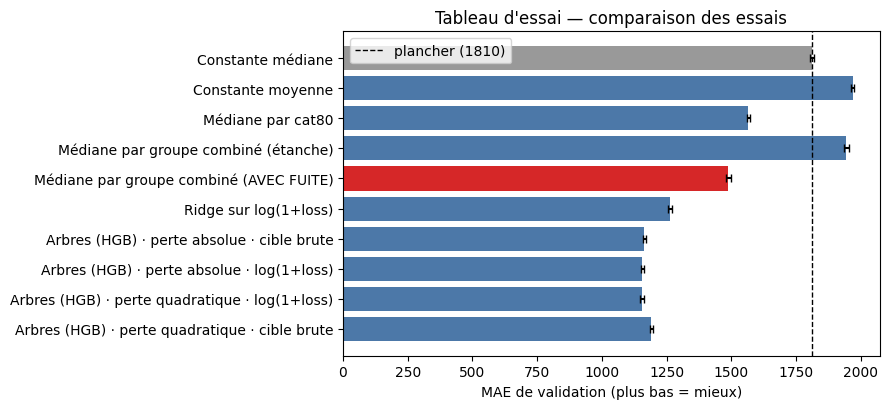

Meilleur essai valide : n°9 — Arbres (HGB) · perte quadratique · log(1+loss) : MAE = 1154.8 ± 6.4 (gain 36.2% vs plancher 1810.5)
essais à égalité avec le meilleur (écart inférieur à un écart-type) : [(8, 'Arbres (HGB) · perte absolue · log(1+loss)'), (9, 'Arbres (HGB) · perte quadratique · log(1+loss)')]


In [17]:
# --- 2.7 (e) Visualiser le journal ---------------------------------------------
fig, ax = plt.subplots(figsize=(9, 4.2))
couleurs = ["#999999" if s == "référence" else "#d62728" if s.startswith("INVALIDE") else "#4C78A8" for s in J.statut]
ax.barh(J.essai[::-1], J.MAE[::-1], xerr=J.écart_type[::-1], color=couleurs[::-1], capsize=3)
ax.axvline(PLANCHER, color="k", ls="--", lw=1, label=f"plancher ({PLANCHER:.0f})")
ax.set_xlabel("MAE de validation (plus bas = mieux)"); ax.set_title("Tableau d'essai — comparaison des essais"); ax.legend()
plt.tight_layout(); plt.show()

meilleur = J[J.statut == "valide"].sort_values("MAE").iloc[0]
print(f"Meilleur essai valide : n°{int(meilleur.n)} — {meilleur.essai} : MAE = {meilleur.MAE} ± {meilleur.écart_type} "
      f"(gain {1 - meilleur.MAE / PLANCHER:.1%} vs plancher {PLANCHER:.1f})")
egalite = J[(J.statut == "valide") & (J.MAE <= meilleur.MAE + meilleur.écart_type)]
print("essais à égalité avec le meilleur (écart inférieur à un écart-type) :", [(int(r.n), r.essai) for _, r in egalite.iterrows()])
RESULTATS["2.7_tableau_essai"] = dict(plancher_MAE=PLANCHER, nb_essais=len(J), meilleur=dict(essai=meilleur.essai, MAE=float(meilleur.MAE), ecart_type=float(meilleur.écart_type)),
    essais=[{k: v for k, v in r.items() if k != "_plis"} for r in JOURNAL])

**Comment lire.** Les barres grises = plancher ; **rouge = essai invalide** (fuite) ; bleu = essais valides. Les traits fins sont les **barres d'incertitude** (± l'écart-type entre plis). Le trait pointillé est le **plancher** : tout essai à **gauche** de cette ligne bat le « sans modèle ». L'essai invalide paraît **excellent**, et c'est exactement le piège : sans les contrôles de l'étanchéité (§2), on l'aurait retenu.

> **Conclusion 2.7 (journal)** : tableau d'essai de 10 essais, tous mesurés avec le même découpage (§1) et la même métrique, avec écart-type, gain vs plancher, durée et verdict ; les échecs (moyenne, groupes trop fins, perte quadratique sur cible brute) et l'essai invalidé par fuite sont **conservés**. La phrase « meilleur essai valide » imprimée ci-dessus donne le score à retenir à ce stade, avec la liste des essais **à égalité** avec lui (différence inférieure à l'écart-type : à départager par d'autres critères, comme la durée ou la cohérence perte/métrique). Fichiers produits : `journal_essais.csv` et `journal_essais.md`.

**Pour la suite (équipe).** Les essais de P2 (barre de bruit, premier modèle) et de P3 (plancher de contrôle, comparaisons) s'ajoutent **dans ce même tableau** avec `consigner(...)` : cela garantit qu'ils sont mesurés sur les mêmes plis.

---
# Bilan et sauvegarde

In [18]:
RESULTATS["fiche_porteur"] = dict(seance=SEANCE, nom=NOM, porteur=PORTEUR, etapes_assignees=ETAPES_ASSIGNEES, date=DATE)
sortie = Path(BASE)
(sortie / "resultats_phase2_P1.json").write_text(json.dumps(RESULTATS, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("écrit :", sortie / "resultats_phase2_P1.json")
print("fichiers produits :", sorted(p.name for p in sortie.glob("*") if p.suffix in (".csv", ".md", ".json") and p.name in ("plis.csv", "journal_essais.csv", "journal_essais.md", "resultats_phase2_P1.json")))

écrit : /kaggle/working/resultats_phase2_P1.json
fichiers produits : ['journal_essais.csv', 'journal_essais.md', 'plis.csv', 'resultats_phase2_P1.json']
